# Exploratory Data Analysis (EDA)
Purpose: Investigate key feature distributions and relationships with crash severity to guide downstream classification and clustering modeling.

Inputs:
* `processed/nsw_crashes_classification.csv`
* `processed/lga_yearly_aggregates_clustering.csv`

Outputs: Visualizations saved to `figures/`

# Setup & DataSet Initialization 

In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats

# Ensure directory for figures exists before saving any figures
os.makedirs("figures", exist_ok=True)

# Load the processed datasets
df_class = pd.read_csv("processed/nsw_crashes_classification.csv")
df_cluster = pd.read_csv("processed/lga_yearly_aggregates_clustering.csv")

# Quick shape verification
print("Classification Data Shape:", df_class.shape)
print("Clustering Data Shape:", df_cluster.shape)

# Clean function to reduce copy-pasted blocks and provide a central metrics logic engine
def compute_categorical_metrics(dataframe, feature_column, target_column="Severe_Crash"):
    """Computes total counts, severe ratios, Chi-Square p-values, and Cramér's V."""
    # Calculate percentage rates per category group
    stats_df = (
        dataframe.groupby(feature_column)
        .agg(
            total_crashes=(target_column, "count"),
            severe_pct=(target_column, lambda x: x.mean() * 100),
        )
        .reset_index()
    )

    # Extract contingency grid and calculate cross-tab matrix scores
    contingency_matrix = pd.crosstab(dataframe[feature_column], dataframe[target_column])
    chi2, p_value, dof, expected = stats.chi2_contingency(contingency_matrix)

    # Calculate Cramér's V (normalized effect size tracking score)
    sample_size = contingency_matrix.sum().sum()
    min_dim = min(contingency_matrix.shape) - 1
    cramers_v = np.sqrt(chi2 / (sample_size * min_dim)) if min_dim > 0 else 0.0

    return stats_df, p_value, cramers_v

Classification Data Shape: (90857, 13)
Clustering Data Shape: (645, 10)


## Section 1: Class Balance
Q: What is the distribution balance between severe and non-severe crashes in the classification model?

Non-Severe (0): 29141 (32.07%) | Severe (1): 61716 (67.93%)


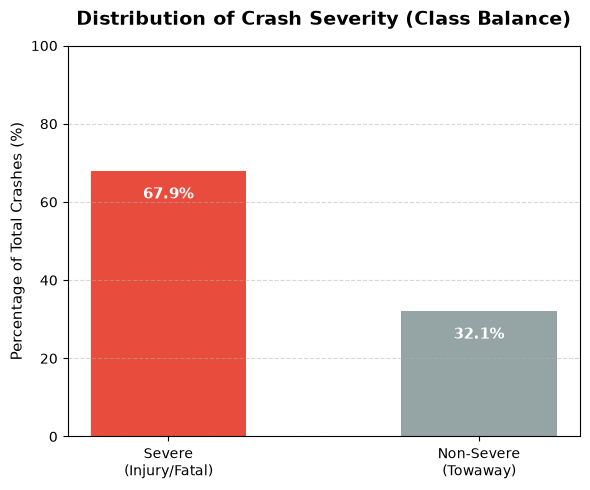

In [2]:
# Compute counts and percentages safely using pandas indexed access keys
count_0 = int(df_class["Severe_Crash"].value_counts().get(0, 0))
count_1 = int(df_class["Severe_Crash"].value_counts().get(1, 0))
total_count = count_0 + count_1

pct_0 = (count_0 / total_count) * 100
pct_1 = (count_1 / total_count) * 100

print(f"Non-Severe (0): {count_0} ({pct_0:.2f}%) | Severe (1): {count_1} ({pct_1:.2f}%)")

# Draw the bar chart using matplotlib
fig, ax = plt.subplots(figsize=(6, 5))
x_labels = ["Severe\n(Injury/Fatal)", "Non-Severe\n(Towaway)"]
y_values = [pct_1, pct_0]

bars = ax.bar(x_labels, y_values, color=["#e74c3c", "#95a5a6"], width=0.5)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.1f}%",
        xy=(bar.get_x() + bar.get_width() / 2, height - 6),
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
        size=11,
    )

ax.set_title(
    "Distribution of Crash Severity (Class Balance)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax.set_ylabel("Percentage of Total Crashes (%)", fontsize=11)
ax.set_ylim(0, 100)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("figures/section1_class_balance.png", dpi=300)
plt.show()

## Interpretation

The target variable distribution contains 67.93% severe incidents (61,716 counts) and 32.07% non-severe incidents (29,141 counts). An unoptimized baseline model that continuously predicts a 'Severe' status would return a base accuracy metric of 67.93%. Consequently, evaluating subsequent machine learning models strictly via overall classification accuracy will yield misleading performance indications. To address this class distribution behavior, down-stream models must prioritize assessment via precision-recall dynamics, confusion matrices, and non-severe F1-scores.

# Section 2: Severity by Weather

Q: How does the proportion of severe crashes vary between different weather conditions, and is weather useful for predicting crash severity?

    Weather  total_crashes  severe_pct
       Fine          72468   69.327151
   Overcast           6138   63.196481
    Raining          11384   62.113493
      Other            138   60.869565
Fog or mist            640   60.781250
    Snowing             89   59.550562

Chi2 p-value: 2.7261e-68 | Cramér's V: 0.0599


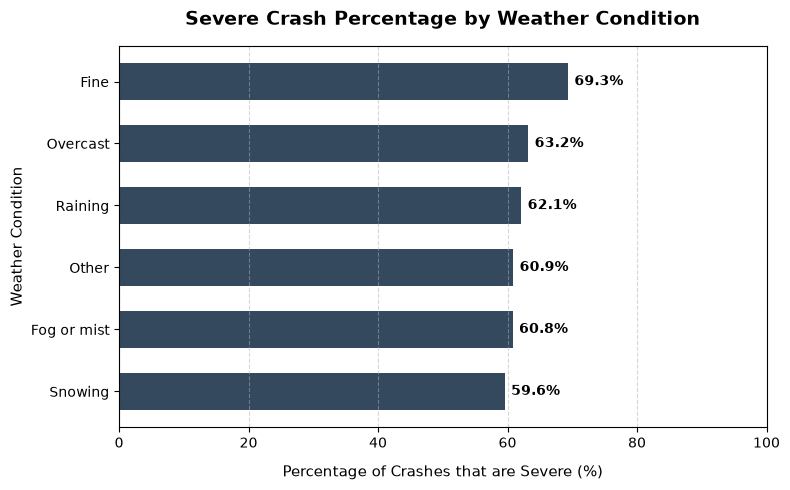

In [3]:
# Compute metrics and tests using the unified helper function
weather_stats, p_val, cv = compute_categorical_metrics(df_class, "Weather")
weather_stats = weather_stats.sort_values(by="severe_pct", ascending=True)

print(
    weather_stats.sort_values(by="severe_pct", ascending=False).to_string(
        index=False
    )
)
print(f"\nChi2 p-value: {p_val:.4e} | Cramér's V: {cv:.4f}")

# Draw horizontal chart layout
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(
    weather_stats["Weather"], weather_stats["severe_pct"], color="#34495e", height=0.6
)

for bar in bars:
    width = bar.get_width()
    ax.annotate(
        f"{width:.1f}%",
        xy=(width + 1, bar.get_y() + bar.get_height() / 2),
        ha="left",
        va="center",
        color="black",
        fontweight="bold",
        size=10,
    )

ax.set_title(
    "Severe Crash Percentage by Weather Condition",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel(
    "Percentage of Crashes that are Severe (%)", fontsize=11, labelpad=10
)
ax.set_ylabel("Weather Condition", fontsize=11)
ax.set_xlim(0, 100)
ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("figures/section2_severity_by_weather.png", dpi=300)
plt.show()

## Interpretation 

Fine conditions exhibit the highest severe-crash share (69.33% across 72,468 records) while Snowing conditions record the minimum proportion at 59.55% (across a small group of 89 observations). While the Chi-Square test confirms that this variance is statistically significant due to our large sample scale ($p < 0.05$), the underlying relationship is exceptionally weak as measured by a Cramér's V effect size of 0.0599. Weather condition is a secondary feature; it will be kept in the feature matrix for background tuning, though it is not expected to contribute significant independent predictive power on its own due to this near-zero association.

# Section 3: Crash Severity by Road Classification

Q: How does the proportion of severe crashes vary across different road classifications, and is it a useful feature for predicting crash severity?

Road classification (admin)  total_crashes  severe_pct
                   Regional          15231   71.787801
                      State          41568   68.482968
                      Local          34058   65.520583

Chi2 p-value: 2.7131e-44 | Cramér's V: 0.0470


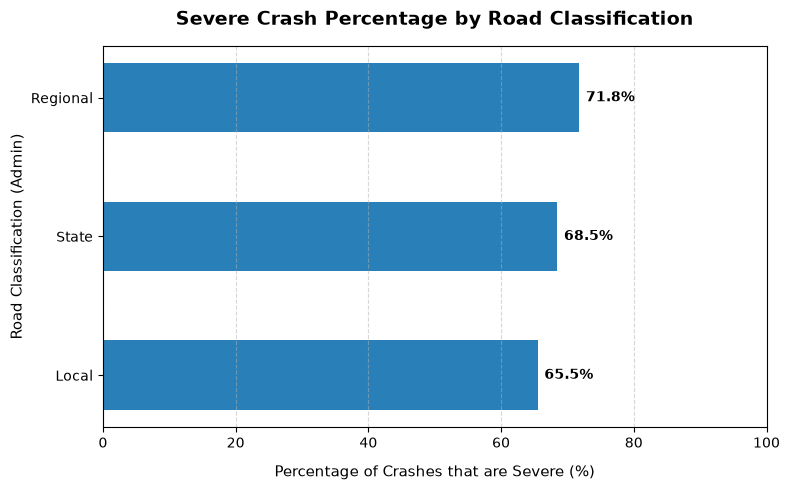

In [4]:
# Compute metrics and tests using the unified helper function
road_stats, p_val, cv = compute_categorical_metrics(
    df_class, "Road classification (admin)"
)
road_stats = road_stats.sort_values(by="severe_pct", ascending=True)

print(
    road_stats.sort_values(by="severe_pct", ascending=False).to_string(
        index=False
    )
)
print(f"\nChi2 p-value: {p_val:.4e} | Cramér's V: {cv:.4f}")

# Draw horizontal chart layout
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(
    road_stats["Road classification (admin)"],
    road_stats["severe_pct"],
    color="#2980b9",
    height=0.5,
)

for bar in bars:
    width = bar.get_width()
    ax.annotate(
        f"{width:.1f}%",
        xy=(width + 1, bar.get_y() + bar.get_height() / 2),
        ha="left",
        va="center",
        color="black",
        fontweight="bold",
        size=10,
    )

ax.set_title(
    "Severe Crash Percentage by Road Classification",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel(
    "Percentage of Crashes that are Severe (%)", fontsize=11, labelpad=10
)
ax.set_ylabel("Road Classification (Admin)", fontsize=11)
ax.set_xlim(0, 100)
ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("figures/section3_severity_by_road_classification.png", dpi=300)
plt.show()

## Interpretation

Regional routes register the most prominent severe distribution ratio at 71.79% (out of 15,231 absolute entries), while local roads anchor the lower boundary at 65.52% (out of 34,058 occurrences), with State corridors sitting in between at 68.48% (out of 41,568 cases). Although the Chi-Square evaluation registers statistical significance ($p < 0.05$), the low metric footprint (Cramér's V = 0.0470) demonstrates that administrative infrastructure designation yields a very weak standalone predictive signal. The severe-crash percentage spread across all three categories remains narrow. Consequently, this attribute should not be used as a primary standalone variable, but can be maintained as a secondary control feature that remains in the model despite providing little independent predictive weight.

# Section 4: Crash Severity by Season 

Q: How does the proportion of severe crashes vary across the four seasons, and does season play a significant role in predicting crash severity?

Season  total_crashes  severe_pct
Summer          22115   68.012661
Autumn          23422   68.059944
Winter          22643   67.005255
Spring          22677   68.624598

Chi2 p-value: 2.6952e-03 | Cramér's V: 0.0125


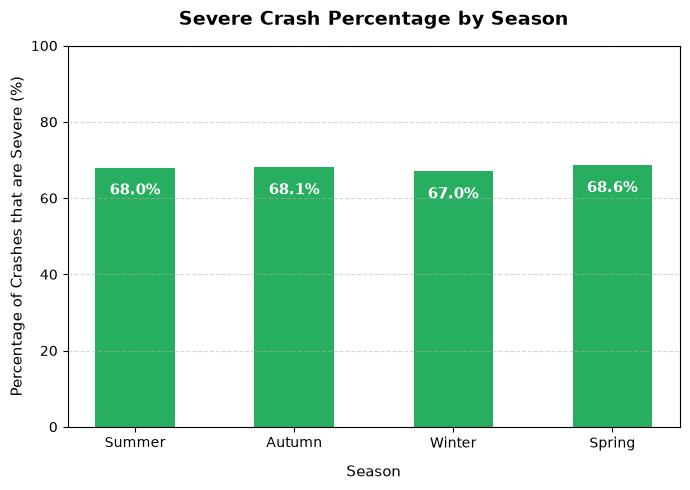

In [5]:
# Force a natural chronological calendar order for evaluation
season_order = ["Summer", "Autumn", "Winter", "Spring"]
df_class["Season"] = pd.Categorical(
    df_class["Season"], categories=season_order, ordered=True
)

# Compute metrics using the unified helper function
season_stats, p_val, cv = compute_categorical_metrics(df_class, "Season")

print(season_stats.to_string(index=False))
print(f"\nChi2 p-value: {p_val:.4e} | Cramér's V: {cv:.4f}")

# Draw vertical chart layout
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(
    season_stats["Season"], season_stats["severe_pct"], color="#27ae60", width=0.5
)

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.1f}%",
        xy=(bar.get_x() + bar.get_width() / 2, height - 6),
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
        size=11,
    )

ax.set_title(
    "Severe Crash Percentage by Season", fontsize=14, fontweight="bold", pad=15
)
ax.set_xlabel("Season", fontsize=11, labelpad=10)
ax.set_ylabel("Percentage of Crashes that are Severe (%)", fontsize=11)
ax.set_ylim(0, 100)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("figures/section4_severity_by_season.png", dpi=300)
plt.show()

## Interpretation

The statistical test gives a low p-value of 0.0027, which proves that the slight differences we see across are unlikely to be due to random chance. However, the connection score of 0.0125 shows that the actual strength of this pattern is negligible. This happens because our dataset is so large that the math detects tiny differences that do not matter in the real world. 

Looking at the percentages, the severe crash rate stays almost perfectly flat all year round, sitting between 67.01% and 68.62% no matter the season. Because the time of year has very weak power to change whether a crash is severe, it is a weak signal on its own. We will classify it as a secondary feature that can be kept in the data matrix for the algorithm to read, though it will not be a major decision maker.

# Section 5: Severity by Speed Limit

Q: Do higher speed limits mean more severe crashes?


 Speed limit  total_crashes  severe_pct
          10             64   81.250000
          20             38   81.578947
          30            190   85.789474
          40           3787   73.567468
          50          30224   63.929328
          60          24920   69.213483
          70           7628   70.267436
          80           8777   73.681212
          90           1278   68.701095
         100          10140   70.128205
         110           3811   60.299134

Chi2 p-value: 1.6337e-124 | Cramér's V: 0.0819


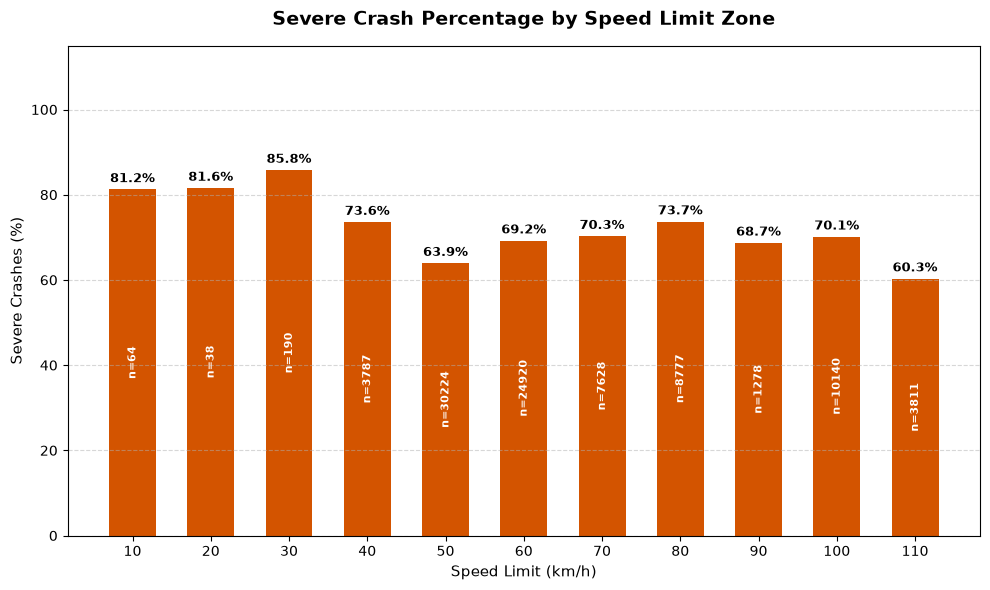

In [6]:
# Compute metrics and tests using the unified helper function
speed_stats, p_val, cv = compute_categorical_metrics(df_class, "Speed limit")
speed_stats = speed_stats.sort_values(by="Speed limit")

print(speed_stats.to_string(index=False))
print(f"\nChi2 p-value: {p_val:.4e} | Cramér's V: {cv:.4f}")

# Draw vertical chart layout
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(
    speed_stats["Speed limit"].astype(str),
    speed_stats["severe_pct"],
    color="#d35400",
    width=0.6,
)

# Label bars with percentages and counts
for bar, row in zip(bars, speed_stats.itertuples()):
    height = bar.get_height()
    ax.annotate(
        f"{height:.1f}%",
        xy=(bar.get_x() + bar.get_width() / 2, height + 1),
        ha="center",
        va="bottom",
        color="black",
        fontweight="bold",
        size=9,
    )
    ax.annotate(
        f"n={row.total_crashes}",
        xy=(bar.get_x() + bar.get_width() / 2, height / 2),
        ha="center",
        va="center",
        color="white",
        rotation=90,
        fontweight="bold",
        size=8,
    )

ax.set_title(
    "Severe Crash Percentage by Speed Limit Zone",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
ax.set_xlabel("Speed Limit (km/h)", fontsize=11)
ax.set_ylabel("Severe Crashes (%)", fontsize=11)
ax.set_ylim(0, 115)
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("figures/section5_severity_by_speed_limit.png", dpi=300)
plt.show()

## Interpretation

The vertical distribution shows that lower speed limit zones register higher severe crash concentrations, peaking at 85.79% in 30 km/h zones. However, one plausible explanation is selective reporting thresholds rather than a direct physical risk gradient. Because low-speed collisions may rarely require a towaway unless an injury occurs, the non-casualty data class could be exceptionally thin here. This is a plausible explanation, not an established one, and it is consistent with the small-sample constraint highlighted by the raw sample size ($n$) counts shown on the chart: the 10, 20, and 30 km/h zones combined contain only 292 total crashes out of the entire dataset.

In contrast, among the high-volume zones with thousands of crashes each, the severe-crash proportion spans a measured range of 60.30% (110 km/h, $n=3,811$) to 73.68% (80 km/h, $n=8,777$), with the dense mid-range zones sitting near the middle (63.93% at 50 km/h, $n=30,224$; 69.21% at 60 km/h, $n=24,920$). The Chi-Square evaluation confirms a statistically significant relationship ($p < 0.001$), and the Cramér's V score of 0.0819 indicates that this variable represents the strongest candidate feature of the four environmental variables analyzed, even though it remains a small absolute effect.

Furthermore, the non-linear pattern, which is characterized by the distinct dip at 50 km/h and a subsequent rise at 80 km/h, implies that speed thresholds present a complex categorical signal that tree-based models are well-suited to handle. Speed limit will be kept in the model as a categorical variable, and its true predictive value will be confirmed by feature importance metrics after model training.


# Section 6: Crash Rate by LGA

Q: What are the top 10 and bottom 10 local government areas (LGAs) by average crash rate per 100,000 population, and how do regional population differences impact these distributions?

--- TOP 10 HIGH-RATE LGAs ---
                 LGA    avg_rate  avg_pop
  Unincorporated NSW 1340.859887   1014.4
     Central Darling  735.379770   1767.0
              Oberon  613.278660   5576.2
              Walcha  584.297299   3010.8
          Carrathool  571.130965   2829.4
       Upper Lachlan  570.187331   8615.2
         Tenterfield  474.684225   6921.8
              Bourke  468.979435   2398.8
         Yass Valley  468.432488  17326.8
Cootamundra-Gundagai  444.757048  11419.8

--- BOTTOM 10 LOW-RATE LGAs ---
             LGA   avg_rate  avg_pop
          Camden 126.221110 127331.2
Northern Beaches 141.109071 267286.0
       Lane Cove 141.554373  40808.8
     Ku-ring-gai 145.080186 126236.4
        Berrigan 149.796396   8679.0
          Mosman 149.946897  28927.2
        Maitland 155.711393  93299.0
        Waverley 162.318982  71066.8
    North Sydney 164.685123  71168.6
    Shellharbour 166.557121  78266.6

Spearman Rank Correlation (Population vs Rate): Rho = -0.5797, p-va

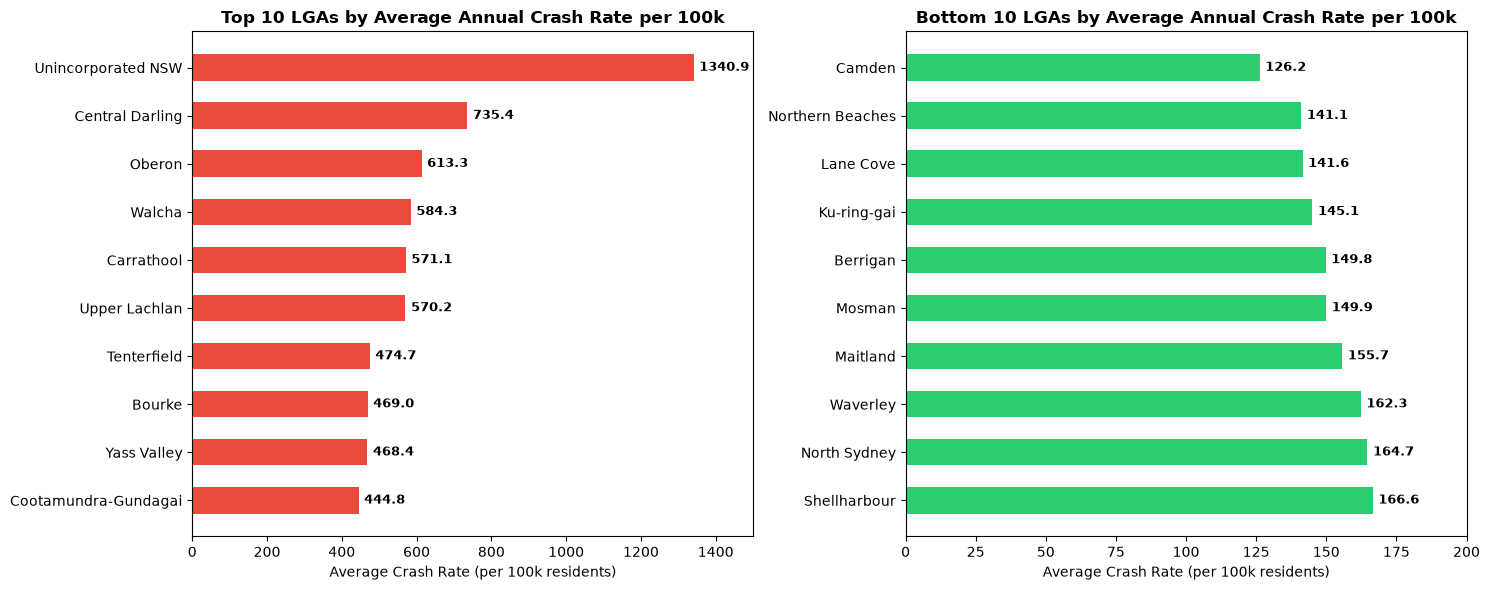

In [7]:
# Compute multi-year average crash rate and average population metrics per LGA
lga_stats = (
    df_cluster.groupby("LGA")
    .agg(
        avg_rate=("Crash rate per 100k", "mean"),
        avg_pop=("Population", "mean"),
    )
    .reset_index()
)

top_10 = (
    lga_stats.sort_values(by="avg_rate", ascending=False)
    .head(10)
    .sort_values(by="avg_rate", ascending=True)
)
bottom_10 = lga_stats.sort_values(by="avg_rate", ascending=True).head(10)

print("--- TOP 10 HIGH-RATE LGAs ---")
print(top_10.sort_values(by="avg_rate", ascending=False).to_string(index=False))
print("\n--- BOTTOM 10 LOW-RATE LGAs ---")
print(bottom_10.to_string(index=False))

# Run an explicit Spearman Rank Correlation test to support population vs rate trends
spearman_rho, spearman_p = stats.spearmanr(lga_stats["avg_pop"], lga_stats["avg_rate"])
print(f"\nSpearman Rank Correlation (Population vs Rate): Rho = {spearman_rho:.4f}, p-value = {spearman_p:.4e}")

# Draw combined horizontal subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

bars1 = ax1.barh(top_10["LGA"], top_10["avg_rate"], color="#e74c3c", height=0.55)
ax1.set_title("Top 10 LGAs by Average Annual Crash Rate per 100k", fontsize=12, fontweight="bold")
ax1.set_xlabel("Average Crash Rate (per 100k residents)", fontsize=10)

for bar in bars1:
    width = bar.get_width()
    ax1.annotate(
        f"{width:.1f}",
        xy=(width + 15, bar.get_y() + bar.get_height() / 2),
        ha="left",
        va="center",
        color="black",
        size=9,
        fontweight="bold",
    )
ax1.set_xlim(0, 1500)

bottom_10_sorted = bottom_10.sort_values(by="avg_rate", ascending=False)
bars2 = ax2.barh(
    bottom_10_sorted["LGA"], bottom_10_sorted["avg_rate"], color="#2ecc71", height=0.55
)
ax2.set_title(
    "Bottom 10 LGAs by Average Annual Crash Rate per 100k",
    fontsize=12,
    fontweight="bold",
)
ax2.set_xlabel("Average Crash Rate (per 100k residents)", fontsize=10)

for bar in bars2:
    width = bar.get_width()
    ax2.annotate(
        f"{width:.1f}",
        xy=(width + 2, bar.get_y() + bar.get_height() / 2),
        ha="left",
        va="center",
        color="black",
        size=9,
        fontweight="bold",
    )
ax2.set_xlim(0, 200)

plt.tight_layout()
plt.savefig("figures/section6_crash_rate_by_lga.png", dpi=300)
plt.show()

## Interpretation

The geographic aggregate demonstrates wide variance in population-adjusted incident metrics, spanning from a minimum floor of 126.2 crashes per 100,000 residents in Camden to an extreme apex of 1,340.9 inside Unincorporated NSW. The Spearman Rank Correlation test confirms a moderate negative trend ($\rho = -0.5797, p < 0.001$). Out of the top 10 highest-rate regions, exactly 8 out of 10 display a small annual population footprint under 10,000 residents (such as Unincorporated NSW at ~1,014 and Central Darling at ~1,767). In these locations, minor absolute increases in accidents can generate volatile spikes in per-capita metrics. These per-capita figures also incorporate external through-traffic, highway transit zones, and seasonal visitors across rural terrain rather than solely reflecting resident safety exposures.

Conversely, the bottom 10 lowest-rate jurisdictions consist mostly of dense, high-volume metropolitan hubs within Greater Sydney, such as Camden (~127,331), Northern Beaches (~267,286), and Ku-ring-gai (~126,236). Their large population bases absorb seasonal traffic changes and absolute incident variations smoothly, keeping the per-capita indices low. This geographic divergence confirms that regional profiling is highly valuable for the downstream clustering algorithm, as it highlights clear demographic variations between regional transport corridors and dense urban centers.